# 03 Первое работающее решение
Для видео используем готовый детектор HOG+SVM из OpenCV. Рамки между кадрами сопоставляются по IoU от 0,3 с сохранением ID до трёх пропущенных кадров. Обучать модель для этой версии не требуется. Трекер запускаем на публичных детекциях MOT17-09 и MOT20-03 и измеряем ошибку подсчёта. Полученные метрики относятся к этому входу, а видеорежим HOG+SVM проверяется отдельно.


In [1]:
from collections import defaultdict
from configparser import ConfigParser
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
from baseline import Tracker, Queue, analyze

series = {}
for dataset, directory in [("MOT17", "MOT17-09-FRCNN"), ("MOT20", "MOT20-03")]:
    scene = Path("data") / dataset / "train" / directory
    info = ConfigParser()
    info.read(scene / "seqinfo.ini")
    frames = info["Sequence"].getint("seqLength")
    truth = np.loadtxt(scene / "gt/gt.txt", delimiter=",", ndmin=2)
    truth = truth[(truth[:, 6] == 1) & (truth[:, 7] == 1)]
    counts = np.bincount(truth[:, 0].astype(int), minlength=frames + 1)[1:]
    detections = np.loadtxt(scene / "det/det.txt", delimiter=",", ndmin=2)
    by_frame = defaultdict(list)
    for row in detections:
        if np.isfinite(row[:7]).all() and row[6] >= 0 and min(row[4:6]) > 0:
            by_frame[int(row[0])].append(row[2:6])
    tracker = Tracker()
    predicted = np.array([len(tracker.update(frame, by_frame[frame]))
                          for frame in range(1, frames + 1)])
    errors = predicted - counts
    series[dataset] = counts, predicted
    print(dataset, "кадров:", frames, "MAE:", round(np.abs(errors).mean(), 2),
          "RMSE:", round(np.sqrt((errors ** 2).mean()), 2))
    if dataset == "MOT17":
        examples = []
        for i in (np.abs(errors).argmin(), np.abs(errors).argmax()):
            print(f"Кадр {i + 1}: разметка {counts[i]}, прогноз {predicted[i]}")

            frame = int(i + 1)
            examples.append((frame, scene, truth[truth[:, 0] == frame, 2:6], by_frame[frame]))

MOT17 кадров: 525 MAE: 4.34 RMSE: 4.66
Кадр 81: разметка 7, прогноз 7
Кадр 288: разметка 13, прогноз 5


MOT20 кадров: 2405 MAE: 56.68 RMSE: 62.68


## Сравнение по кадрам

Сравниваем число пешеходов из разметки с числом детекций, которым назначены ID. Обе кривые построены только для валидационных видеосцен.

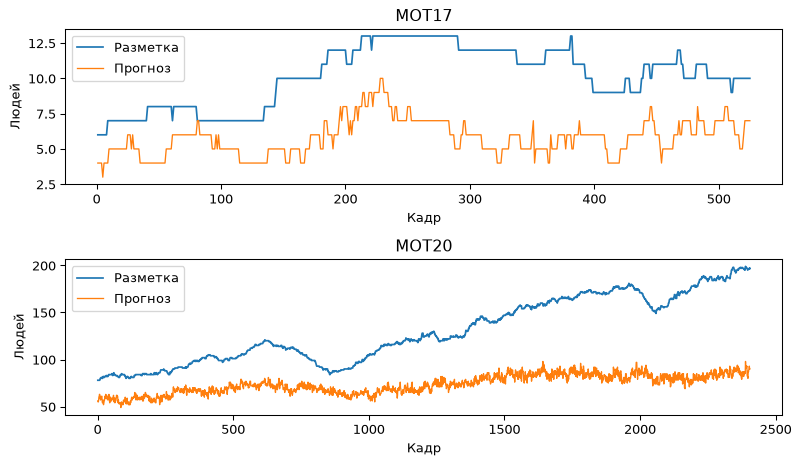

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(8.5, 5), dpi=95)
for ax, (dataset, (actual, predicted)) in zip(axes, series.items()):
    frames = np.arange(1, len(actual) + 1)
    ax.plot(frames, actual, label="Разметка", linewidth=1.3)
    ax.plot(frames, predicted, label="Прогноз", linewidth=1.0)
    ax.set(title=dataset, xlabel="Кадр", ylabel="Людей")
    ax.legend()
fig.tight_layout()
plt.show()


## Примеры результата

Показаны кадры MOT17-09 с минимальной и максимальной ошибкой подсчёта. Зелёные рамки взяты из разметки, оранжевые — публичные детекции после назначения ID. В первом кадре число людей совпало, хотя рамки могут различаться. Во втором кадре часть людей не обнаружена. Исходные кадры взяты из [MOT17](https://motchallenge.net/data/MOT17/). Для повторного построения с фотографиями нужны соответствующие JPG в `img1`.

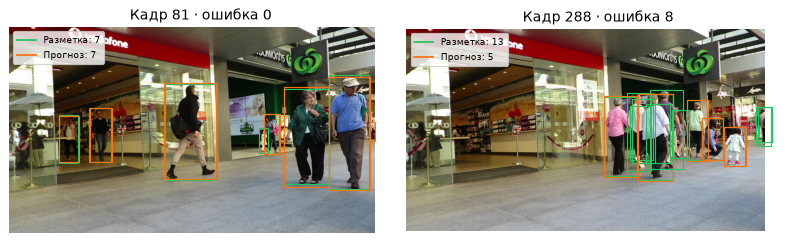

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), dpi=85)
for ax, (frame, scene, actual, predicted) in zip(axes, examples):
    path = scene / "img1" / f"{frame:06d}.jpg"
    if path.is_file():
        ax.imshow(plt.imread(path))
    else:
        ax.set(xlim=(0, 1920), ylim=(1080, 0), aspect="equal")
    for boxes, color, label in [(actual, "#22c55e", "Разметка"),
                                (predicted, "#f97316", "Прогноз")]:
        ax.plot([], [], color=color, label=f"{label}: {len(boxes)}")
        for x, y, width, height in boxes:
            ax.add_patch(Rectangle((x, y), width, height, fill=False, ec=color, lw=1))
    ax.set_title(f"Кадр {frame} · ошибка {abs(len(actual) - len(predicted))}")
    ax.legend(loc="upper left", fontsize=8)
    ax.axis("off")
fig.tight_layout()
plt.show()


В плотной сцене MOT20 ошибка выше. MAE и RMSE измеряют ошибку в людях на кадр. Время ожидания проверяем отдельно на известной траектории, потому что в разметке MOT нет событий очереди.


In [4]:
tracker = Tracker()
first_id = tracker.update(1, [(10, 10, 30, 60)])[0][0]
assert tracker.update(2, [(15, 10, 30, 60)])[0][0] == first_id
queue = Queue((0, 0, 50, 100), (50, 0, 100, 100), fps=2, area=2)
waiting = queue.update(1, [(1, (10, 10, 10, 20))], {1})
served = queue.update(4, [(1, (60, 10, 10, 20))], {1})
assert waiting["queue_length"] == 1 and waiting["density_m2"] == .5
assert served["queue_length"] == 0 and served["completed_wait_s"] == [1.5]
print(waiting)
print(served)


{'visible': 1, 'queue_length': 1, 'density_m2': 0.5, 'completed_wait_s': []}
{'visible': 1, 'queue_length': 0, 'density_m2': 0.0, 'completed_wait_s': [1.5]}


## Запуск
```bash
.venv/bin/python baseline.py data/example.mp4 --output queue.jsonl
```

Настройки зон задаются параметрами командной строки. Порог IoU и правила сопоставления сохранены в `baseline.py`. Предобученный детектор поставляется с OpenCV. При перекрытии людей детектор пропускает рамки, а трекер может потерять ID.


In [5]:
video = Path("data/example.mp4")
if video.is_file():
    frames = analyze(str(video), (10, 80, 300, 360), (300, 80, 400, 360), None, "queue.jsonl")
    assert len(Path("queue.jsonl").read_text().splitlines()) == frames
    print("Обработано кадров:", frames)
    print(Path("queue.jsonl").read_text().splitlines()[0])
else:
    print("Для видеопроверки поместите MP4 в data/example.mp4.")


Обработано кадров: 8
{"frame": 1, "visible": 1, "queue_length": 0, "density_m2": null, "completed_wait_s": []}
